# 7. Cleaning up and mastering the sound

After pitch correction, the whole song goes through one "tone chain" and a master stage
(`tone.process_source` and `mastering.master`):

`high-pass → noise reduction → automatic EQ → de-esser → compressor → reverb → loudness + peak limiting`

Each stage follows the project's rule: **measure first, then move part of the way, with hard caps**. This
notebook explains each one, and the real-world lesson about hiss that shaped the EQ.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

from songpolish import tone, mastering
from songpolish.analysis import band_levels_db, band_snr_db, loudness_lufs
from pedalboard import Pedalboard, LowShelfFilter, PeakFilter, HighShelfFilter, HighpassFilter
rng = np.random.default_rng(0)

## 7.1 Noise and the noise floor

Phone recordings have **background noise**: hiss (broadband, like "shhh"), hum from electrical mains,
room noise. The quietest moments of a recording (pauses) contain only that noise: the **noise floor**.

A useful number is the **signal-to-noise ratio (SNR)** per frequency band: how much louder the music is than the
noise floor. `analysis.band_snr_db` measures it in octave bands: level while playing vs level in the quietest
2% of frames. On the real song every band had only 20–28 dB of SNR. Not much.

In [2]:
song = voice_like([57, 60, 62, 64, 62, 60], note_s=0.6, gap_s=0.35)
hiss = (0.004 * rng.standard_normal(song.shape)).astype(np.float32)
noisy = song + hiss
play(noisy, label="voice + hiss")
snr = band_snr_db(noisy, tone.EQ_BANDS)
for fc, s in zip(tone.EQ_BANDS, snr):
    print(f"band around {int(fc):5d} Hz: SNR {s:5.1f} dB")

voice + hiss


band around   100 Hz: SNR   3.6 dB
band around   200 Hz: SNR  49.7 dB
band around   400 Hz: SNR  46.3 dB
band around   800 Hz: SNR  39.7 dB
band around  1600 Hz: SNR  33.5 dB
band around  3200 Hz: SNR  25.6 dB
band around  6400 Hz: SNR   2.8 dB
band around 12800 Hz: SNR   2.6 dB


The voice's energy is in the middle bands (200 Hz – 3 kHz). The lowest band and the high bands hold almost
only hiss, hence their low SNR.

## 7.2 Noise reduction by spectral gating

**Spectral gating** (the `noisereduce` library):

1. learn the noise's spectrum from the quietest passages (the app picks the quietest 10% of frames),
2. in every time-frequency bin, if the level is not clearly above that noise (1.5 standard deviations), turn it
   **down**,
3. invert the STFT.

The crucial choice is *how much* to turn down. Removing noise bins completely (a full gate) leaves a sound
that flickers between "something" and "nothing", heard as **"underwater"** or **"musical noise"**. The app
never goes below `prop_decrease = 0.25 + 0.6 × amount` (0.55 at the default, about −7 dB): the hiss is
reduced, never removed.

In [3]:
import noisereduce as nr
gentle = tone.denoise(noisy, 0.5)
full_gate = nr.reduce_noise(y=noisy, sr=SR, prop_decrease=1.0, stationary=True)
for name, y in [("noisy", noisy), ("app (0.5)", gentle), ("full gate", full_gate)]:
    gap = y[0, int(0.62 * SR): int(0.9 * SR)]                       # a pause between notes
    print(f"{name:10s}: noise in a pause {20 * np.log10(np.sqrt(np.mean(gap ** 2)) + 1e-9):6.1f} dB")
play(gentle, label="app: hiss reduced, sound natural")
play(full_gate, label="full gate: silent pauses, but listen to the tails of the notes (artefacts)")

noisy     : noise in a pause  -47.8 dB
app (0.5) : noise in a pause  -54.4 dB
full gate : noise in a pause  -86.8 dB
app: hiss reduced, sound natural


full gate: silent pauses, but listen to the tails of the notes (artefacts)


## 7.3 EQ: filters that shape the tone

An **equaliser (EQ)** turns frequency regions up or down. The app uses three kinds of filters:

* **low shelf**: raise or lower everything below a frequency (bass),
* **peak**: raise or lower a bell-shaped region around a frequency (e.g. cut "boxiness" around 400 Hz),
* **high shelf**: raise or lower everything above a frequency (treble, "air").

Below are their **frequency responses**: what each filter does to every frequency. You get it by passing
an impulse (a single click, which contains all frequencies equally) through the filter and taking the FFT.

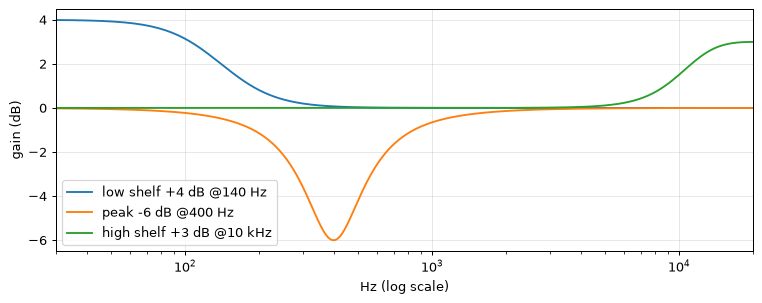

In [4]:
impulse = np.zeros((1, 16384), np.float32); impulse[0, 0] = 1
fig, ax = plt.subplots(figsize=(10, 3.5))
for f, lab in [(LowShelfFilter(140, gain_db=4, q=0.7), "low shelf +4 dB @140 Hz"),
               (PeakFilter(400, gain_db=-6, q=1.4), "peak -6 dB @400 Hz"),
               (HighShelfFilter(10000, gain_db=3, q=0.7), "high shelf +3 dB @10 kHz")]:
    r = np.abs(np.fft.rfft(f(impulse, SR)[0])); freqs = np.fft.rfftfreq(16384, 1 / SR)
    ax.semilogx(freqs[1:], 20 * np.log10(r[1:]), label=lab)
ax.set_xlim(30, 20000); ax.set_xlabel("Hz (log scale)"); ax.set_ylabel("gain (dB)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 7.4 Automatic EQ: measure, compare with a target, move part of the way

`tone.auto_eq`:

1. **measure** the long-term average spectrum in 8 octave bands (100 Hz … 12.8 kHz), relative to their
   average (only the *shape* matters, not the volume),
2. compare with a **target shape**, a rough average of well-produced acoustic recordings
   (`TARGET_SPECTRUM`, one per source type),
3. set each band's gain to `tone_match × (target − measured)` (0.6 by default: part of the way),
4. **cap** it: at most −8 dB of cut and +6 dB of boost, never boost a nearly empty band,
5. re-measure twice and correct, because neighbouring filters overlap.

A typical phone take is ~10 dB too **boomy** (200–400 Hz) and ~9 dB too **dull** (little treble). Let's fake
one and let the EQ fix it.

filters chosen: [('LowShelfFilter', 140, -2.0), ('PeakFilter', 200, -1.5), ('PeakFilter', 400, -2.4), ('PeakFilter', 800, 1.1), ('PeakFilter', 1600, 0.4), ('PeakFilter', 3200, 2.0), ('PeakFilter', 6400, 2.9), ('HighShelfFilter', 10000, -0.5)]


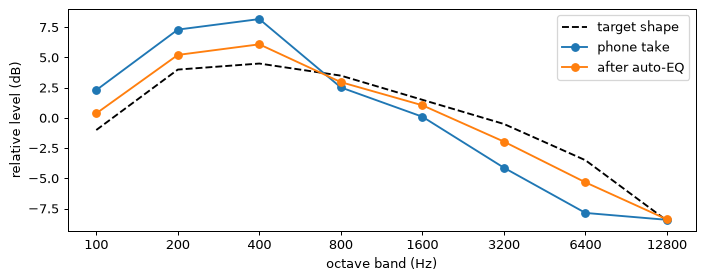

In [5]:
# Stand-in for music: bursts of *pink* noise (equal energy per octave, like most music), 0.6 s on, 0.3 s off.
n = 20 * SR
spec = np.fft.rfft(rng.standard_normal(n)); freqs = np.fft.rfftfreq(n, 1 / SR)
spec[1:] /= np.sqrt(freqs[1:]); spec[0] = 0
pink = np.fft.irfft(spec, n); pink = 0.1 * pink / pink.std()
gate = (np.arange(n) % int(0.9 * SR)) < 0.6 * SR
pink_music = (pink * gate)[None].astype(np.float32)
phone = Pedalboard([PeakFilter(300, gain_db=10, q=1.0), HighShelfFilter(3000, gain_db=-9, q=0.7)])(pink_music, SR)   # boomy + dull
target = tone.TARGET_SPECTRUM[tone.Source.MIX] - tone.TARGET_SPECTRUM[tone.Source.MIX].mean()
eq = tone.auto_eq(phone, tone.Source.MIX, 0.6)
after = eq(phone, SR)
print("filters chosen:", [(type(f).__name__, int(f.cutoff_frequency_hz), round(f.gain_db, 1)) for f in eq])
fig, ax = plt.subplots(figsize=(9, 3.2))
x = np.arange(len(tone.EQ_BANDS))
ax.plot(x, target, "k--", label="target shape"); ax.plot(x, band_levels_db(phone, tone.EQ_BANDS), "o-", label="phone take")
ax.plot(x, band_levels_db(after, tone.EQ_BANDS), "o-", label="after auto-EQ")
ax.set_xticks(x); ax.set_xticklabels([f"{int(f)}" for f in tone.EQ_BANDS]); ax.set_xlabel("octave band (Hz)"); ax.set_ylabel("relative level (dB)")
ax.legend(); plt.show()

### The "old recorder" lesson: never boost hiss

On the real song the user said the result sounded **"as if recorded with an old recorder"**. The cause: the
take was dull, so the EQ boosted the treble +6 dB. But in a dull phone take the treble is **mostly hiss**, so
the hiss went up ~9 dB.

Two rules fixed it:

1. **A band may only be boosted as far as its SNR allows**: no boost below 30 dB SNR, the full +6 dB only
   from 45 dB. Boosting a band boosts its noise too.
2. **Relative to the overall change**: the song is loudness-normalised later (7.6). If the EQ cuts the boomy
   low-mids (where most of the energy is), normalisation turns *everything else* up. That is a hidden treble
   boost. So in the treble (≥ 2.5 kHz) the boost limit applies *relative to the overall level change*: the boom
   still goes, the hiss does not come up.

Here the same dull signal, once clean and once with hiss:

In [6]:
music = (0.1 * rng.standard_normal(n) * gate)[None].astype(np.float32)   # white-noise bursts: energy in every band
dull = HighShelfFilter(3000, gain_db=-25, q=0.7)(music, SR)
for label, y in [("clean dull take", dull + 1e-7 * rng.standard_normal(dull.shape).astype(np.float32)),
                 ("dull take with hiss", dull + 0.003 * rng.standard_normal(dull.shape).astype(np.float32))]:
    board = tone.auto_eq(y, tone.Source.VOCAL, 1.0)
    treble = max(f.gain_db for f in board if f.cutoff_frequency_hz >= 6000)
    print(f"{label:20s}: treble SNR {band_snr_db(y, tone.EQ_BANDS)[-1]:5.1f} dB -> treble gain {treble:+.1f} dB")

clean dull take     : treble SNR  95.1 dB -> treble gain +5.8 dB


dull take with hiss : treble SNR   6.7 dB -> treble gain -1.2 dB


## 7.5 De-esser and compressor: evening out

**De-esser.** "S" and "t" sounds are bursts of noise above ~5 kHz that can be piercing. The de-esser splits
the signal at 5.5 kHz, follows the loudness of the top band, and turns only that band down when it spikes
above its usual level (its 90th percentile). Vowels are untouched.

**Compressor.** Singers are louder on some notes than others. A compressor reduces that range:

* below a **threshold**, nothing happens,
* above it, every extra dB of input gives only 1/**ratio** dB of output (ratio 2.75:1 for the voice at the default),
* **attack** (8 ms) and **release** (90 ms) set how fast it reacts, so it follows phrases rather than single waves.

The threshold is set from the measured level (`active_rms_db`, ignoring silences), so the compressor behaves
the same on a quiet and a loud recording. After compression the song is turned back up (7.6), so quiet notes
end up relatively louder.

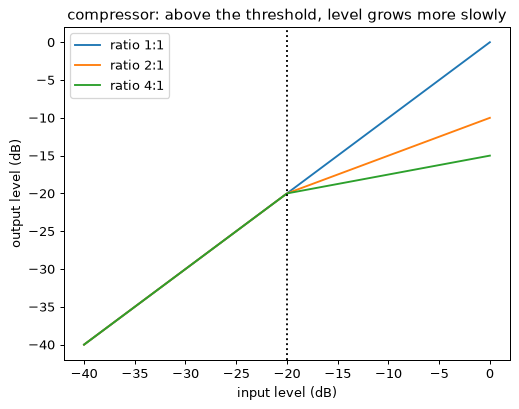

note levels before (dB): [-31.6 -16.  -25.5 -13.5 -28.6]  range 18.1 dB
note levels after  (dB): [-31.6 -20.5 -25.5 -19.8 -28.6]  range 11.7 dB


In [7]:
level_in = np.linspace(-40, 0, 200)
for ratio in [1.0, 2.0, 4.0]:
    thr = -20
    out = np.where(level_in < thr, level_in, thr + (level_in - thr) / ratio)
    plt.plot(level_in, out, label=f"ratio {ratio:.0f}:1")
plt.axvline(-20, color="k", ls=":"); plt.xlabel("input level (dB)"); plt.ylabel("output level (dB)")
plt.title("compressor: above the threshold, level grows more slowly"); plt.legend(); plt.show()

uneven = np.concatenate([voice_like([60], note_s=0.6, amp=a) for a in (0.05, 0.3, 0.1, 0.4, 0.07)], axis=1)
comp = tone.compressor(uneven, 0.8, tone.Source.VOCAL)(uneven, SR)
def note_levels(y):
    return [20 * np.log10(np.sqrt(np.mean(y[0, int((0.1 + 0.68 * k) * SR): int((0.5 + 0.68 * k) * SR)] ** 2))) for k in range(5)]
li, lo = note_levels(uneven), note_levels(comp)
print("note levels before (dB):", np.round(li, 1), f" range {max(li) - min(li):.1f} dB")
print("note levels after  (dB):", np.round(lo, 1), f" range {max(lo) - min(lo):.1f} dB")

## 7.6 Space and mastering

**Reverb.** A dry phone take sounds small. Real rooms add thousands of tiny echoes (the room's **impulse
response**, its "fingerprint"). The app adds a small, damped artificial room (`mastering.add_space`, the
Freeverb algorithm via pedalboard), at 30% of the "space" setting.

**Mastering.** The last stage:

1. gentle **bus compression** ("glue"),
2. **loudness normalisation** to the target (−14 LUFS by default, what streaming services use),
3. a **true-peak limiter** at −1 dBTP. Digital audio can't exceed ±1, and the waveform *between* samples can
   overshoot when converted to sound, so the limiter checks the oversampled ("true") peak and turns down only
   the few loudest moments.

**Honest A/B.** The app also exports your original at **the same loudness** (`loudness_match`, with only a
transparent limiter). Louder always sounds "better" to our ears, so comparing against a quieter original
would be cheating.

In [8]:
dry = voice_like([57, 60, 64, 69], note_s=0.5)
wet = mastering.add_space(dry, 0.3, vocal=True)
mastered = mastering.master(wet, target_lufs=-14.0, true_peak_db=-1.0)
reference = mastering.loudness_match(dry, -14.0, -1.0)
print(f"dry: {loudness_lufs(dry):6.1f} LUFS, peak {20 * np.log10(np.abs(dry).max()):5.1f} dBFS")
print(f"mastered: {loudness_lufs(mastered):6.1f} LUFS, peak {20 * np.log10(np.abs(mastered).max()):5.1f} dBFS")
print(f"reference for A/B: {loudness_lufs(reference):6.1f} LUFS")
play(dry, label="dry"); play(mastered, label="with space, mastered")

dry:  -17.4 LUFS, peak -10.0 dBFS
mastered:  -14.0 LUFS, peak  -8.1 dBFS
reference for A/B:  -14.0 LUFS
dry


with space, mastered


## Summary

| stage | measures | then | caps |
|---|---|---|---|
| noise reduction | noise spectrum from the quietest 10% | turns noise bins down | never a full gate (≥ 45% kept at default) |
| auto-EQ | octave-band spectrum vs a target | moves 60% of the way | −8/+6 dB; no boost of empty or noisy bands; treble relative to the overall change |
| de-esser | top-band loudness | ducks spikes only | ≤ 10 dB |
| compressor | active level | threshold from it | moderate ratios, slow enough to keep the phrasing |
| master | LUFS, true peak | normalise + limit | −14 LUFS, −1 dBTP |

Next: **notebook 8**, the whole pipeline on a real recording.